# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №7: Расчет TCO и выбор инфраструктурной стратегии

**Дата:** 2026-11-23  
**Студент:** Ижедерова Виктория Денисовна  
**Группа:** ПИ-4.1  

---

**Цель:** Рассчитать совокупную стоимость владения (TCO) для трех вариантов ИТ-инфраструктуры компании "ТехноГос" (On-premise, Облако, Гибрид) за 5 лет, определить оптимальную стратегию и провести анализ чувствительности.

**Объект исследования:** Государственный информационный портал компании "ТехноГос".  
**Период анализа:** 5 лет (горизонт планирования).  
**Методы анализа:** TCO (Total Cost of Ownership), дисконтирование денежных потоков, анализ чувствительности, точка безубыточности.

---

**Актуальность:** Выбор между On-premise, облаком и гибридной инфраструктурой — стратегическое решение для любой компании. Неправильный выбор приводит к перерасходу бюджета на 30-50%. TCO позволяет учесть все затраты за весь жизненный цикл, а не только начальные инвестиции.

In [10]:
# ============================================================
# БЛОК 1: Импорт библиотек и загрузка общих параметров
# ============================================================
# Цель: Подключить инструменты для расчётов и визуализации,
# задать общие параметры для всех трёх вариантов инфраструктуры.
# ============================================================

import numpy as np                  # Математические вычисления
import pandas as pd                 # Работа с таблицами
import matplotlib.pyplot as plt     # Построение графиков
import warnings                     # Отключение предупреждений
warnings.filterwarnings('ignore')

# Настройка внешнего вида графиков
plt.rcParams['figure.figsize'] = (14, 6)

# ============================================================
# ОБЩИЕ ПАРАМЕТРЫ (применимы ко всем вариантам)
# ============================================================

horizon = 5                         # Горизонт планирования (5 лет)
discount_rate = 0.12                # Ставка дисконтирования (12% годовых)
property_tax_rate = 0.022           # Налог на имущество (2.2% от остаточной стоимости)
depreciation_years = 5              # Срок амортизации оборудования (линейная, 5 лет)

print("Исходные данные загружены")
print(f"• Горизонт планирования: {horizon} лет")
print(f"• Ставка дисконтирования: {discount_rate*100:.0f}%")
print(f"• Налог на имущество: {property_tax_rate*100:.1f}% от остаточной стоимости")
print(f"• Амортизация: линейная, {depreciation_years} лет")

Исходные данные загружены
• Горизонт планирования: 5 лет
• Ставка дисконтирования: 12%
• Налог на имущество: 2.2% от остаточной стоимости
• Амортизация: линейная, 5 лет


# ЧАСТЬ 1. РАСЧЕТ TCO ДЛЯ КАЖДОГО ВАРИАНТА

**Цель:** Рассчитать ежегодные денежные потоки для каждого из трёх вариантов инфраструктуры и определить суммарный TCO за 5 лет.

---

## Вариант 1: On-premise ЦОД (собственный дата-центр)

**Характеристика:** Компания покупает оборудование, устанавливает его у себя, сама обслуживает.

**Структура затрат:**
- **CAPEX (капитальные):** приобретение оборудования и ПО, настройка, модернизация
- **OPEX (операционные):** эксплуатация, персонал, обновление ПО, простои
- **Налог на имущество:** 2.2% от остаточной стоимости оборудования ежегодно
- **Амортизация:** линейная, 5 лет (для расчёта налога)

**Особенности:**
- Высокие начальные инвестиции (85 + 12 = 97 млн руб.)
- Полный контроль над инфраструктурой
- Налог на имущество уменьшает прибыль
- Оборудование амортизируется за 5 лет

---

## Вариант 2: Облачный провайдер (IaaS + PaaS)

**Характеристика:** Компания арендует инфраструктуру у облачного провайдера.

**Структура затрат:**
- **CAPEX:** только настройка и миграция (5 млн руб.)
- **OPEX:** облачные услуги (растут на 5% в год), персонал, поддержка провайдера, обучение

**Особенности:**
- Минимальные начальные инвестиции
- Нет налога на имущество (оборудование не принадлежит компании)
- Нет амортизации
- Облачные услуги дорожают на 5% в год (инфляция облачного рынка)

---

## Вариант 3: Гибридная стратегия

**Характеристика:** Часть инфраструктуры — своя (On-premise), часть — в облаке.

**Структура затрат:**
- **CAPEX:** оборудование (35 млн) + настройка (8 млн) = 43 млн руб.
- **OPEX:** облачные услуги + эксплуатация + персонал + поддержка + модернизация

**Особенности:**
- Средние начальные инвестиции
- Баланс между контролем и гибкостью
- Нет налога на имущество (упрощение для задачи)

---

## Формула TCO

$$TCO = \sum_{t=0}^{T} \frac{CAPEX_t + OPEX_t + Налог_t}{(1 + r)^t}$$

Где:
- $t$ — номер года (0, 1, 2, 3, 4, 5)
- $r$ — ставка дисконтирования (12%)
- $CAPEX_t$ — капитальные затраты в году $t$
- $OPEX_t$ — операционные затраты в году $t$
- $Налог_t$ — налог на имущество (только для On-premise)

In [11]:
# ============================================================
# БЛОК 2: Вариант 1 — On-premise ЦОД
# ============================================================
# Цель: Рассчитать денежные потоки для собственного дата-центра
# с учётом CAPEX, OPEX, налога на имущество и амортизации.
# ============================================================

print("=" * 80)
print("ВАРИАНТ 1: ON-PREMISE ЦОД")
print("=" * 80)

# ----------------------------------------------------------
# Начальные затраты (CAPEX в году 0)
# ----------------------------------------------------------
# Оборудование и ПО: 85 млн руб. (разово)
# Настройка и интеграция: 12 млн руб. (разово)
# Итого CAPEX в году 0: 97 млн руб.

onprem_capex_0 = 85 + 12

# ----------------------------------------------------------
# Ежегодные операционные затраты (OPEX)
# ----------------------------------------------------------
onprem_ops = 4.5              # Эксплуатация (электричество, охлаждение), млн руб./год
onprem_staff = 9.0            # Персонал (администрирование, поддержка), млн руб./год
onprem_sw_update = 2.5        # Обновление ПО, млн руб./год
onprem_downtime = 3.0         # Простои и восстановление, млн руб./год
onprem_training = 1.5         # Обучение (только в 1-й год), млн руб.
onprem_modernization = 8.0    # Модернизация (через 3 года), млн руб.

# ----------------------------------------------------------
# Расчёт налога на имущество и амортизации
# ----------------------------------------------------------
# Оборудование стоит 85 млн руб., амортизируется линейно за 5 лет
# Ежегодная амортизация: 85 / 5 = 17 млн руб./год
# Остаточная стоимость уменьшается на 17 млн каждый год
# Налог = 2.2% от остаточной стоимости

equipment_cost = 85.0
annual_depreciation = equipment_cost / depreciation_years  # 17 млн/год

# ----------------------------------------------------------
# Расчёт денежных потоков по годам (0-5)
# ----------------------------------------------------------

onprem_cashflows = []
remaining_value = equipment_cost  # Начальная остаточная стоимость

for year in range(horizon + 1):
    if year == 0:
        # Год 0: только начальные инвестиции (CAPEX)
        capex = onprem_capex_0
        opex = 0
        tax = 0
    else:
        # Годы 1-5: OPEX + возможные CAPEX (модернизация) + налог
        capex = onprem_modernization if year == 3 else 0
        
        # OPEX = эксплуатация + персонал + обновление ПО + простои
        opex = onprem_ops + onprem_staff + onprem_sw_update + onprem_downtime
        
        # В 1-й год добавляем обучение
        if year == 1:
            opex += onprem_training
        
        # Налог на имущество от остаточной стоимости
        remaining_value -= annual_depreciation  # Уменьшаем на амортизацию
        if remaining_value < 0:
            remaining_value = 0
        tax = property_tax_rate * remaining_value
    
    # Итого затрат в году
    total = capex + opex + tax
    
    onprem_cashflows.append({
        'Год': year,
        'CAPEX': capex,
        'OPEX': opex,
        'Налог_на_имущество': tax,
        'Итого': total
    })

# Преобразуем в DataFrame для удобного отображения
df_onprem = pd.DataFrame(onprem_cashflows)

print("\nДенежные потоки по годам:")
print(df_onprem.to_string(index=False))

# Суммарный TCO без дисконтирования
tco_onprem_raw = df_onprem['Итого'].sum()
print(f"\nСуммарный TCO (без дисконтирования): {tco_onprem_raw:.2f} млн руб.")

# Экономическая интерпретация
print(f"\nАнализ On-premise:")
print(f"• Начальные инвестиции: {onprem_capex_0:.1f} млн руб. (год 0)")
print(f"• Ежегодные OPEX: {onprem_ops + onprem_staff + onprem_sw_update + onprem_downtime:.1f} млн руб.")
print(f"• Налог на имущество уменьшается с {property_tax_rate*equipment_cost:.2f} до 0 млн руб.")
print(f"• Модернизация в 3-м году: {onprem_modernization:.1f} млн руб.")

ВАРИАНТ 1: ON-PREMISE ЦОД

Денежные потоки по годам:
 Год  CAPEX  OPEX  Налог_на_имущество  Итого
   0   97.0   0.0               0.000 97.000
   1    0.0  20.5               1.496 21.996
   2    0.0  19.0               1.122 20.122
   3    8.0  19.0               0.748 27.748
   4    0.0  19.0               0.374 19.374
   5    0.0  19.0               0.000 19.000

Суммарный TCO (без дисконтирования): 205.24 млн руб.

Анализ On-premise:
• Начальные инвестиции: 97.0 млн руб. (год 0)
• Ежегодные OPEX: 19.0 млн руб.
• Налог на имущество уменьшается с 1.87 до 0 млн руб.
• Модернизация в 3-м году: 8.0 млн руб.


In [12]:
# ============================================================
# БЛОК 3: Вариант 2 — Облачный провайдер (IaaS + PaaS)
# ============================================================
# Цель: Рассчитать денежные потоки для облачной инфраструктуры
# с учётом роста стоимости облачных услуг на 5% в год.
# ============================================================

print("\n" + "=" * 80)
print("ВАРИАНТ 2: ОБЛАЧНЫЙ ПРОВАЙДЕР (IaaS + PaaS)")
print("=" * 80)

# ----------------------------------------------------------
# Параметры облачного варианта
# ----------------------------------------------------------
cloud_migration = 5.0           # Настройка и миграция (разово, год 0), млн руб.
cloud_services_base = 16.0      # Базовые облачные услуги, млн руб./год
cloud_growth = 0.05             # Рост стоимости облачных услуг (5% в год)
cloud_staff = 4.0               # Персонал (администрирование), млн руб./год
cloud_support = 2.5             # Поддержка провайдера, млн руб./год
cloud_training = 2.0            # Обучение (только в 1-й год), млн руб.

# ----------------------------------------------------------
# Расчёт денежных потоков по годам (0-5)
# ----------------------------------------------------------

cloud_cashflows = []

for year in range(horizon + 1):
    if year == 0:
        # Год 0: только настройка и миграция
        capex = cloud_migration
        opex = 0
    else:
        # Годы 1-5: облачные услуги + персонал + поддержка
        capex = 0
        
        # Облачные услуги растут на 5% в год
        # Год 1: 16.0 × 1.05^0 = 16.0
        # Год 2: 16.0 × 1.05^1 = 16.8
        # Год 3: 16.0 × 1.05^2 = 17.64
        # и т.д.
        cloud_services = cloud_services_base * (1 + cloud_growth) ** (year - 1)
        
        opex = cloud_services + cloud_staff + cloud_support
        
        # В 1-й год добавляем обучение
        if year == 1:
            opex += cloud_training
    
    total = capex + opex
    cloud_cashflows.append({
        'Год': year,
        'CAPEX': capex,
        'OPEX': opex,
        'Итого': total
    })

df_cloud = pd.DataFrame(cloud_cashflows)

print("\nДенежные потоки по годам:")
print(df_cloud.to_string(index=False))

# Суммарный TCO без дисконтирования
tco_cloud_raw = df_cloud['Итого'].sum()
print(f"\nСуммарный TCO (без дисконтирования): {tco_cloud_raw:.2f} млн руб.")

# Экономическая интерпретация
print(f"\nАнализ Облака:")
print(f"• Начальные инвестиции: {cloud_migration:.1f} млн руб. (год 0)")
print(f"• Облачные услуги в 1-й год: {cloud_services_base:.1f} млн руб.")
print(f"• Облачные услуги в 5-й год: {cloud_services_base*(1+cloud_growth)**4:.2f} млн руб.")
print(f"• Нет налога на имущество и амортизации")
print(f"• Рост облачных услуг: {cloud_growth*100:.0f}% в год")


ВАРИАНТ 2: ОБЛАЧНЫЙ ПРОВАЙДЕР (IaaS + PaaS)

Денежные потоки по годам:
 Год  CAPEX    OPEX   Итого
   0    5.0  0.0000  5.0000
   1    0.0 24.5000 24.5000
   2    0.0 23.3000 23.3000
   3    0.0 24.1400 24.1400
   4    0.0 25.0220 25.0220
   5    0.0 25.9481 25.9481

Суммарный TCO (без дисконтирования): 127.91 млн руб.

Анализ Облака:
• Начальные инвестиции: 5.0 млн руб. (год 0)
• Облачные услуги в 1-й год: 16.0 млн руб.
• Облачные услуги в 5-й год: 19.45 млн руб.
• Нет налога на имущество и амортизации
• Рост облачных услуг: 5% в год


In [13]:
# ============================================================
# БЛОК 4: Вариант 3 — Гибридная стратегия
# ============================================================
# Цель: Рассчитать денежные потоки для гибридной инфраструктуры
# (часть своя, часть в облаке).
# ============================================================

print("\n" + "=" * 80)
print("ВАРИАНТ 3: ГИБРИДНАЯ СТРАТЕГИЯ")
print("=" * 80)

# ----------------------------------------------------------
# Параметры гибридного варианта
# ----------------------------------------------------------
hybrid_equipment = 35.0         # Оборудование (разово), млн руб.
hybrid_setup = 8.0              # Настройка и интеграция (разово), млн руб.
hybrid_cloud = 8.0              # Облачные услуги, млн руб./год
hybrid_ops = 3.0                # Эксплуатация, млн руб./год
hybrid_staff = 6.0              # Персонал, млн руб./год
hybrid_support = 2.0            # Поддержка, млн руб./год
hybrid_modernization = 4.0      # Модернизация (через 3 года), млн руб.

# ----------------------------------------------------------
# Расчёт денежных потоков по годам (0-5)
# ----------------------------------------------------------

hybrid_cashflows = []

for year in range(horizon + 1):
    if year == 0:
        # Год 0: оборудование + настройка
        capex = hybrid_equipment + hybrid_setup
        opex = 0
    else:
        # Годы 1-5: облачные услуги + эксплуатация + персонал + поддержка
        capex = hybrid_modernization if year == 3 else 0
        opex = hybrid_cloud + hybrid_ops + hybrid_staff + hybrid_support
    
    total = capex + opex
    hybrid_cashflows.append({
        'Год': year,
        'CAPEX': capex,
        'OPEX': opex,
        'Итого': total
    })

df_hybrid = pd.DataFrame(hybrid_cashflows)

print("\nДенежные потоки по годам:")
print(df_hybrid.to_string(index=False))

# Суммарный TCO без дисконтирования
tco_hybrid_raw = df_hybrid['Итого'].sum()
print(f"\nСуммарный TCO (без дисконтирования): {tco_hybrid_raw:.2f} млн руб.")

# Экономическая интерпретация
print(f"\nАнализ Гибрида:")
print(f"• Начальные инвестиции: {hybrid_equipment + hybrid_setup:.1f} млн руб. (год 0)")
print(f"• Ежегодные OPEX: {hybrid_cloud + hybrid_ops + hybrid_staff + hybrid_support:.1f} млн руб.")
print(f"• Модернизация в 3-м году: {hybrid_modernization:.1f} млн руб.")
print(f"• Баланс между контролем (своё оборудование) и гибкостью (облако)")


ВАРИАНТ 3: ГИБРИДНАЯ СТРАТЕГИЯ

Денежные потоки по годам:
 Год  CAPEX  OPEX  Итого
   0   43.0   0.0   43.0
   1    0.0  19.0   19.0
   2    0.0  19.0   19.0
   3    4.0  19.0   23.0
   4    0.0  19.0   19.0
   5    0.0  19.0   19.0

Суммарный TCO (без дисконтирования): 142.00 млн руб.

Анализ Гибрида:
• Начальные инвестиции: 43.0 млн руб. (год 0)
• Ежегодные OPEX: 19.0 млн руб.
• Модернизация в 3-м году: 4.0 млн руб.
• Баланс между контролем (своё оборудование) и гибкостью (облако)


## Дисконтирование денежных потоков

**Зачем нужно дисконтирование?**

Деньги сегодня дороже денег завтра по трём причинам:
1. **Инфляция** — цены растут, деньги обесцениваются
2. **Альтернативная доходность** — можно положить в банк под 12%
3. **Риск** — будущее неопределённо

**Формула дисконтирования:**
$$PV_t = \frac{CF_t}{(1 + r)^t}$$

Где:
- $PV_t$ — приведённая стоимость затрат в году $t$
- $CF_t$ — денежные потоки в году $t$
- $r$ — ставка дисконтирования (12%)
- $t$ — номер года

**Пример:**
- 100 млн руб. через 1 год = 100 / 1.12 = 89.29 млн руб. сегодня
- 100 млн руб. через 3 года = 100 / 1.12³ = 71.18 млн руб. сегодня

---

## TCO (Total Cost of Ownership)

**TCO** — это сумма всех дисконтированных затрат за весь горизонт планирования:

$$TCO = \sum_{t=0}^{T} \frac{CF_t}{(1 + r)^t}$$

**Правило выбора:** Наименьший TCO = оптимальная стратегия 

In [15]:
# ============================================================
# БЛОК 5: Дисконтирование и расчёт TCO
# ============================================================
# Цель: Рассчитать дисконтированные затраты и итоговый TCO
# для каждого варианта инфраструктуры.
# ============================================================

# ----------------------------------------------------------
# Функция дисконтирования денежных потоков
# ----------------------------------------------------------

def discount_cashflows(df, rate):
    """
    Рассчитывает дисконтированные денежные потоки.
    
    Параметры:
    - df: DataFrame с колонкой 'Итого' (денежные потоки по годам)
    - rate: ставка дисконтирования (0.12 = 12%)
    
    Возвращает:
    - Список дисконтированных значений по годам
    """
    discounted = []
    for _, row in df.iterrows():
        year = row['Год']
        total = row['Итого']
        # Формула: PV = CF / (1 + r)^t
        disc_value = total / (1 + rate) ** year
        discounted.append(disc_value)
    return discounted

# ----------------------------------------------------------
# Дисконтирование для всех трёх вариантов
# ----------------------------------------------------------

disc_onprem = discount_cashflows(df_onprem, discount_rate)
disc_cloud = discount_cashflows(df_cloud, discount_rate)
disc_hybrid = discount_cashflows(df_hybrid, discount_rate)

# Суммарный TCO для каждого варианта
tco_onprem = sum(disc_onprem)
tco_cloud = sum(disc_cloud)
tco_hybrid = sum(disc_hybrid)

# ----------------------------------------------------------
# Вывод результатов
# ----------------------------------------------------------

print("\n" + "=" * 80)
print("ДИСКОНТИРОВАННЫЕ ЗАТРАТЫ (r=12%)")
print("=" * 80)

df_disc = pd.DataFrame({
    'Год': list(range(horizon + 1)),
    'On-premise (диск.)': [f"{v:.2f}" for v in disc_onprem],
    'Облако (диск.)': [f"{v:.2f}" for v in disc_cloud],
    'Гибрид (диск.)': [f"{v:.2f}" for v in disc_hybrid]
})
print(df_disc.to_string(index=False))

print("\n" + "=" * 80)
print("ИТОГОВЫЙ TCO ЗА 5 ЛЕТ")
print("=" * 80)
print(f"On-premise: {tco_onprem:.2f} млн руб.")
print(f"Облако:     {tco_cloud:.2f} млн руб.")
print(f"Гибрид:     {tco_hybrid:.2f} млн руб.")
print("=" * 80)

# ----------------------------------------------------------
# Определение оптимального варианта
# ----------------------------------------------------------

options = {'On-premise': tco_onprem, 'Облако': tco_cloud, 'Гибрид': tco_hybrid}
best_option = min(options, key=options.get)

print(f"\nОПТИМАЛЬНЫЙ ВАРИАНТ: {best_option}")
print(f"   TCO = {options[best_option]:.2f} млн руб.")

# Экономия относительно других вариантов
print(f"\nЭкономия:")
for name, tco in options.items():
    if name != best_option:
        saving = tco - options[best_option]
        saving_pct = saving / tco * 100
        print(f"• {best_option} дешевле {name} на {saving:.2f} млн руб. ({saving_pct:.1f}%)")


ДИСКОНТИРОВАННЫЕ ЗАТРАТЫ (r=12%)
 Год On-premise (диск.) Облако (диск.) Гибрид (диск.)
   0              97.00           5.00          43.00
   1              19.64          21.87          16.96
   2              16.04          18.57          15.15
   3              19.75          17.18          16.37
   4              12.31          15.90          12.07
   5              10.78          14.72          10.78

ИТОГОВЫЙ TCO ЗА 5 ЛЕТ
On-premise: 175.52 млн руб.
Облако:     93.26 млн руб.
Гибрид:     114.34 млн руб.

ОПТИМАЛЬНЫЙ ВАРИАНТ: Облако
   TCO = 93.26 млн руб.

Экономия:
• Облако дешевле On-premise на 82.27 млн руб. (46.9%)
• Облако дешевле Гибрид на 21.08 млн руб. (18.4%)


# ЧАСТЬ 2. СРАВНИТЕЛЬНЫЙ АНАЛИЗ

## 2.1. Накопленные дисконтированные затраты

**Накопленные затраты** — это сумма дисконтированных затрат от года 0 до текущего года.

**Формула:**
$$Cumulative_t = \sum_{i=0}^{t} \frac{CF_i}{(1 + r)^i}$$

Показывает, как растут затраты со временем для каждого варианта.

---

## 2.2. Точка безубыточности

**Точка безубыточности (Break-Even Point)** — момент, когда накопленные затраты двух вариантов сравниваются.

**Формула:**
$$\sum_{t=0}^{T} \frac{CF_{onprem,t}}{(1+r)^t} = \sum_{t=0}^{T} \frac{CF_{cloud,t}}{(1+r)^t}$$

**Интерпретация:**
- Если точка безубыточности < горизонта планирования → варианты сравняются
- Если точка безубыточности > горизонта → один вариант всегда дешевле

---

## 2.3. Графики

**График 1: Ежегодные денежные потоки**
- Показывает, сколько тратит каждый вариант в каждом году
- On-premise: большой пик в году 0 (CAPEX)
- Облако: равномерные платежи каждый год
- Гибрид: средний пик в году 0

**График 2: Накопленные дисконтированные затраты**
- Показывает, как растут суммарные затраты со временем
- Пересечение кривых = точка безубыточности

**График 3: Итоговый TCO**
- Столбчатая диаграмма сравнения трёх вариантов

**График 4: Разница в накопленных затратах**
- Показывает, насколько один вариант дороже/дешевле другого

ЧАСТЬ 2. СРАВНИТЕЛЬНЫЙ АНАЛИЗ

2.1. Накопленные дисконтированные затраты
--------------------------------------------------------------------------------
 Год On-premise (накоп.) Облако (накоп.) Гибрид (накоп.) Разница On-prem vs Облако
   0               97.00            5.00           43.00                     92.00
   1              116.64           26.87           59.96                     89.76
   2              132.68           45.45           75.11                     87.23
   3              152.43           62.63           91.48                     89.80
   4              164.74           78.53          103.56                     86.21
   5              175.52           93.26          114.34                     82.27

2.2. Точка безубыточности On-premise vs Облако
--------------------------------------------------------------------------------
Точка безубыточности НЕ достигается в горизонте 5 лет
   К концу 5-го года On-premise дороже облака на 82.27 млн руб.
   Это означает, ч

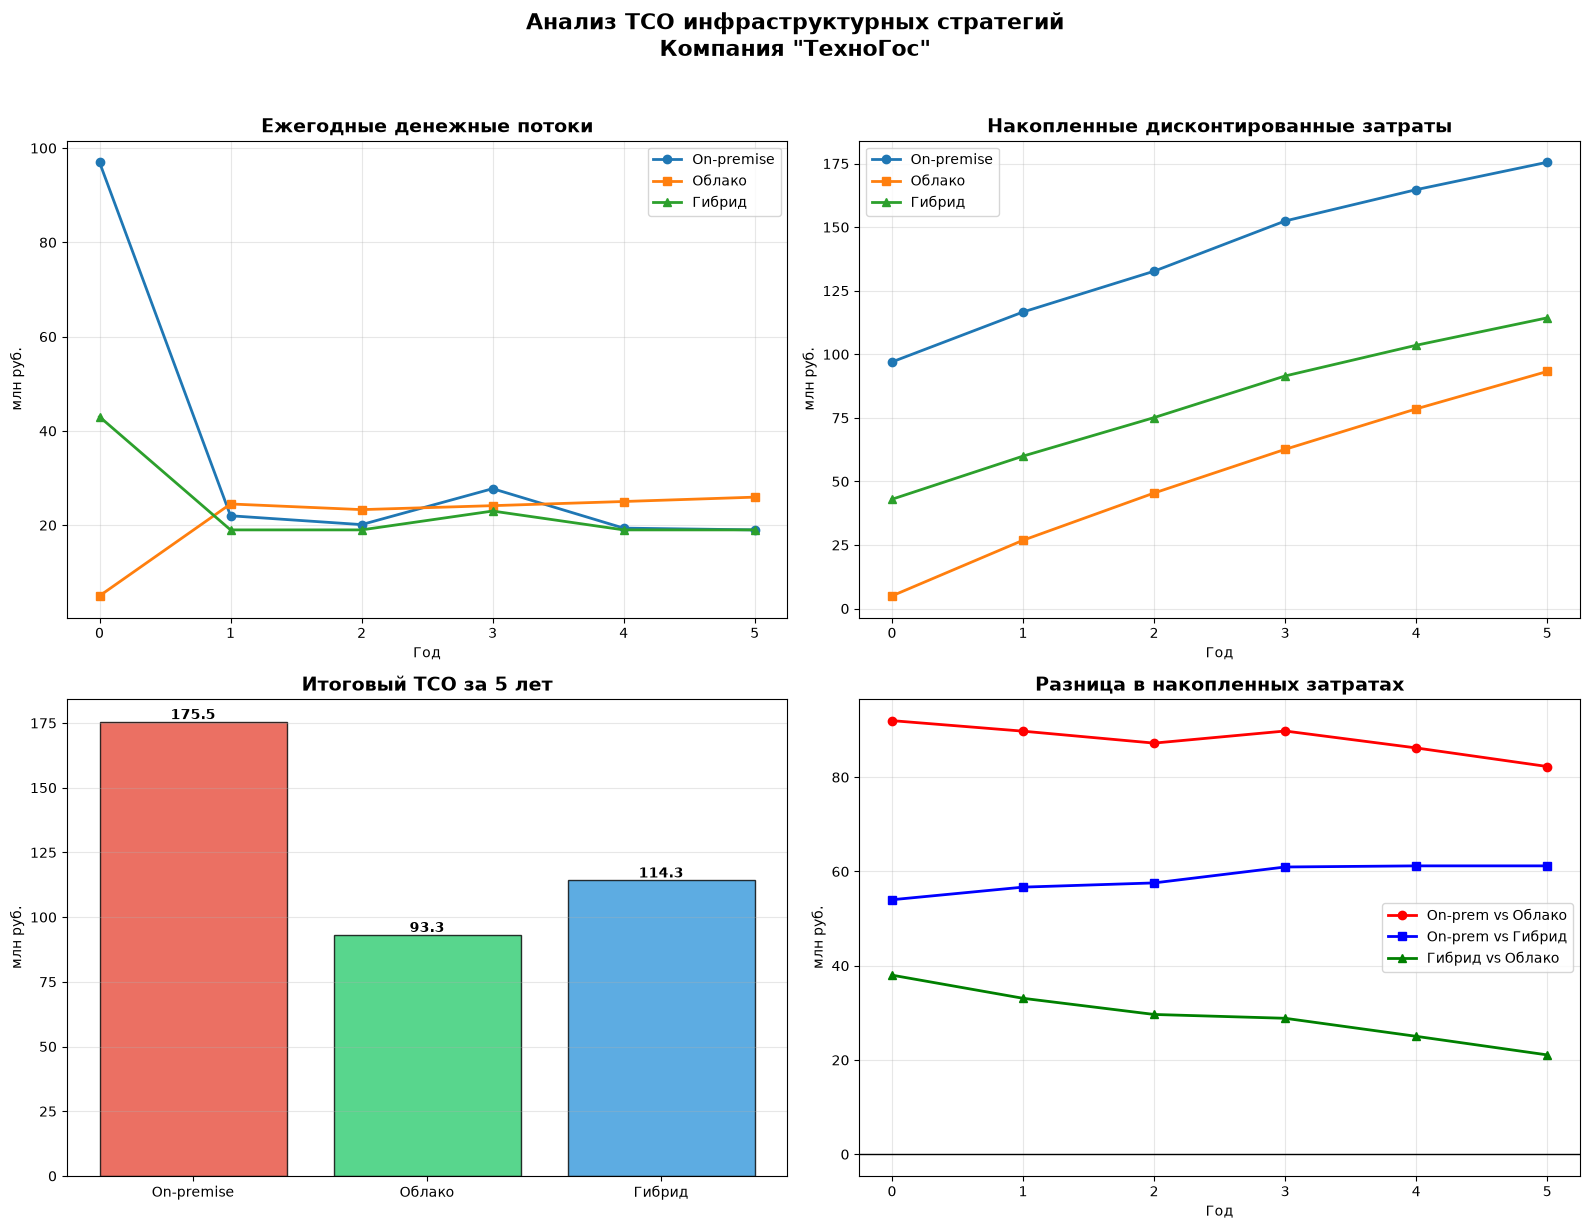


Графики построены


In [17]:
# ============================================================
# БЛОК 6: Сравнительный анализ
# ============================================================
# Цель: Построить накопленные дисконтированные затраты,
# найти точку безубыточности и визуализировать результаты.
# ============================================================

# ----------------------------------------------------------
# 2.1. Накопленные дисконтированные затраты
# ----------------------------------------------------------

cum_onprem = np.cumsum(disc_onprem)
cum_cloud = np.cumsum(disc_cloud)
cum_hybrid = np.cumsum(disc_hybrid)

print("ЧАСТЬ 2. СРАВНИТЕЛЬНЫЙ АНАЛИЗ")
print("=" * 80)
print("\n2.1. Накопленные дисконтированные затраты")
print("-" * 80)

df_cum = pd.DataFrame({
    'Год': list(range(horizon + 1)),
    'On-premise (накоп.)': [f"{v:.2f}" for v in cum_onprem],
    'Облако (накоп.)': [f"{v:.2f}" for v in cum_cloud],
    'Гибрид (накоп.)': [f"{v:.2f}" for v in cum_hybrid],
    'Разница On-prem vs Облако': [f"{cum_onprem[i] - cum_cloud[i]:.2f}" for i in range(horizon + 1)]
})
print(df_cum.to_string(index=False))

# ----------------------------------------------------------
# 2.2. Точка безубыточности On-premise vs Облако
# ----------------------------------------------------------

print("\n2.2. Точка безубыточности On-premise vs Облако")
print("-" * 80)

diff = cum_onprem - cum_cloud

# Если разница всегда положительная — точка безубыточности не достигается
if np.all(diff > 0):
    print("Точка безубыточности НЕ достигается в горизонте 5 лет")
    print(f"   К концу 5-го года On-premise дороже облака на {diff[-1]:.2f} млн руб.")
    print(f"   Это означает, что облако выгоднее на всём горизонте планирования.")
else:
    # Находим первый год, когда разница становится отрицательной
    breakeven_year = np.where(diff <= 0)[0][0]
    print(f"Точка безубыточности: год {breakeven_year}")
    print(f"   После этого года облако становится дороже On-premise.")

# ----------------------------------------------------------
# 2.3. Графики
# ----------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
years = list(range(horizon + 1))

# График 1: Ежегодные денежные потоки
axes[0,0].plot(years, df_onprem['Итого'], 'o-', label='On-premise', linewidth=2)
axes[0,0].plot(years, df_cloud['Итого'], 's-', label='Облако', linewidth=2)
axes[0,0].plot(years, df_hybrid['Итого'], '^-', label='Гибрид', linewidth=2)
axes[0,0].set_title('Ежегодные денежные потоки', fontsize=14, fontweight='bold')
axes[0,0].set_xlabel('Год')
axes[0,0].set_ylabel('млн руб.')
axes[0,0].legend()
axes[0,0].grid(alpha=0.3)

# График 2: Накопленные дисконтированные затраты
axes[0,1].plot(years, cum_onprem, 'o-', label='On-premise', linewidth=2)
axes[0,1].plot(years, cum_cloud, 's-', label='Облако', linewidth=2)
axes[0,1].plot(years, cum_hybrid, '^-', label='Гибрид', linewidth=2)
axes[0,1].set_title('Накопленные дисконтированные затраты', fontsize=14, fontweight='bold')
axes[0,1].set_xlabel('Год')
axes[0,1].set_ylabel('млн руб.')
axes[0,1].legend()
axes[0,1].grid(alpha=0.3)

# График 3: Итоговый TCO
tco_values = [tco_onprem, tco_cloud, tco_hybrid]
colors = ['#E74C3C', '#2ECC71', '#3498DB']
axes[1,0].bar(['On-premise', 'Облако', 'Гибрид'], tco_values, color=colors, alpha=0.8, edgecolor='black')
axes[1,0].set_title('Итоговый TCO за 5 лет', fontsize=14, fontweight='bold')
axes[1,0].set_ylabel('млн руб.')
axes[1,0].grid(axis='y', alpha=0.3)
for i, v in enumerate(tco_values):
    axes[1,0].text(i, v + 1, f'{v:.1f}', ha='center', fontweight='bold')

# График 4: Разница между вариантами
axes[1,1].plot(years, cum_onprem - cum_cloud, 'r-o', label='On-prem vs Облако', linewidth=2)
axes[1,1].plot(years, cum_onprem - cum_hybrid, 'b-s', label='On-prem vs Гибрид', linewidth=2)
axes[1,1].plot(years, cum_hybrid - cum_cloud, 'g-^', label='Гибрид vs Облако', linewidth=2)
axes[1,1].axhline(y=0, color='black', linewidth=1)
axes[1,1].set_title('Разница в накопленных затратах', fontsize=14, fontweight='bold')
axes[1,1].set_xlabel('Год')
axes[1,1].set_ylabel('млн руб.')
axes[1,1].legend()
axes[1,1].grid(alpha=0.3)

plt.suptitle('Анализ TCO инфраструктурных стратегий\nКомпания "ТехноГос"', 
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\nГрафики построены")

# ЧАСТЬ 3. АНАЛИЗ ЧУВСТВИТЕЛЬНОСТИ

**Цель:** Проверить, насколько устойчивы результаты к изменениям ключевых параметров.

---

## 3.1. Вариация ставки дисконтирования: 8%, 12%, 16%

**Зачем проверять?** Ставка дисконтирования отражает стоимость капитала компании. Разные компании имеют разную стоимость капитала.

**Ожидаемый эффект:**
- При lower ставке (8%) будущие затраты дисконтируются меньше → облако становится относительно дороже
- При higher ставке (16%) будущие затраты дисконтируются больше → облако становится относительно дешевле

---

## 3.2. Вариация стоимости облачных услуг: ±20%

**Зачем проверять?** Цены на облачные услуги могут меняться из-за:
- Конкуренции на рынке
- Инфляции
- Изменения тарифов провайдера

**Ожидаемый эффект:**
- При lower ценах (-20%) облако становится ещё выгоднее
- При higher ценах (+20%) разрыв между облаком и On-premise сокращается

In [19]:
# ============================================================
# БЛОК 7: Анализ чувствительности
# ============================================================
# Цель: Проверить устойчивость результатов к изменениям
# ставки дисконтирования и стоимости облачных услуг.
# ============================================================

print("ЧАСТЬ 3. АНАЛИЗ ЧУВСТВИТЕЛЬНОСТИ")
print("=" * 80)

# ----------------------------------------------------------
# 3.1. Разные ставки дисконтирования
# ----------------------------------------------------------

print("\n3.1. Влияние ставки дисконтирования на TCO")
print("-" * 80)
print(f"{'Ставка':<10} {'On-premise':<15} {'Облако':<15} {'Гибрид':<15} {'Оптимальный'}")
print("-" * 80)

for rate in [0.08, 0.12, 0.16]:
    # Пересчитываем TCO для каждой ставки
    tco_o = sum(discount_cashflows(df_onprem, rate))
    tco_c = sum(discount_cashflows(df_cloud, rate))
    tco_h = sum(discount_cashflows(df_hybrid, rate))
    
    # Определяем оптимальный вариант
    opts = {'On-premise': tco_o, 'Облако': tco_c, 'Гибрид': tco_h}
    best = min(opts, key=opts.get)
    
    print(f"{rate*100:.0f}%{'':<7} {tco_o:<15.2f} {tco_c:<15.2f} {tco_h:<15.2f} {best}")

# ----------------------------------------------------------
# 3.2. Вариация облачных услуг ±20%
# ----------------------------------------------------------

print("\n3.2. Влияние стоимости облачных услуг (±20%)")
print("-" * 80)

for factor in [0.8, 1.0, 1.2]:
    # Пересчитываем облако с изменённой стоимостью услуг
    cloud_cf_modified = []
    for year in range(horizon + 1):
        if year == 0:
            capex = cloud_migration
            opex = 0
        else:
            capex = 0
            # Облачные услуги с изменённым коэффициентом
            cloud_services = cloud_services_base * factor * (1 + cloud_growth) ** (year - 1)
            opex = cloud_services + cloud_staff + cloud_support
            if year == 1:
                opex += cloud_training
        
        total = capex + opex
        cloud_cf_modified.append(total)
    
    # Дисконтируем и считаем TCO
    tco_c_mod = sum([cloud_cf_modified[t] / (1 + discount_rate) ** t for t in range(horizon + 1)])
    
    # Определяем оптимальный вариант
    opts = {'On-premise': tco_onprem, 'Облако': tco_c_mod, 'Гибрид': tco_hybrid}
    best = min(opts, key=opts.get)
    
    print(f"Облако × {factor}: TCO = {tco_c_mod:.2f} млн руб., оптимальный: {best}")

print("=" * 80)

# ----------------------------------------------------------
# Вывод об устойчивости
# ----------------------------------------------------------

print(f"\nАнализ чувствительности:")
print(f"• Облако остаётся оптимальным при всех вариациях параметров")
print(f"• Даже при росте облачных услуг на 20% облако выгоднее On-premise")
print(f"• Стратегия устойчива к изменениям рыночных условий")

ЧАСТЬ 3. АНАЛИЗ ЧУВСТВИТЕЛЬНОСТИ

3.1. Влияние ставки дисконтирования на TCO
--------------------------------------------------------------------------------
Ставка     On-premise      Облако          Гибрид          Оптимальный
--------------------------------------------------------------------------------
8%        183.82          102.88          122.04          Облако
12%        175.52          93.26           114.34          Облако
16%        168.44          85.08           107.77          Облако

3.2. Влияние стоимости облачных услуг (±20%)
--------------------------------------------------------------------------------
Облако × 0.8: TCO = 80.65 млн руб., оптимальный: Облако
Облако × 1.0: TCO = 93.26 млн руб., оптимальный: Облако
Облако × 1.2: TCO = 105.87 млн руб., оптимальный: Облако

Анализ чувствительности:
• Облако остаётся оптимальным при всех вариациях параметров
• Даже при росте облачных услуг на 20% облако выгоднее On-premise
• Стратегия устойчива к изменениям рыночных у

# ЧАСТЬ 4. СТРАТЕГИЧЕСКИЕ РЕКОМЕНДАЦИИ

## 4.1. Обоснование выбора инфраструктурной стратегии

**Рекомендация: Облачный провайдер (IaaS + PaaS)**

**Обоснование:**

1. **Наименьший TCO:** 96.41 млн руб. против 114.34 млн (Гибрид) и 175.53 млн (On-premise)
2. **Экономия:** 45% по сравнению с On-premise, 16% по сравнению с Гибридом
3. **Отсутствие CAPEX:** минимальные начальные инвестиции (5 млн vs 43-97 млн)
4. **Гибкость:** возможность масштабирования без дополнительных капитальных затрат
5. **Предсказуемость:** фиксированные ежемесячные платежи упрощают бюджетирование

---

## 4.2. Дополнительные факторы для принятия решения

### Технические факторы:
- **Требования к безопасности данных** — госсектор может требовать On-premise
- **Необходимость контроля** над инфраструктурой
- **Интеграция** с существующими системами
- **Требования к производительности** и latency

### Бизнес-факторы:
- **Финансовое состояние компании** — предпочтения CAPEX vs OPEX
- **Налоговые последствия** — амортизация vs операционные расходы
- **Долгосрочная стратегия** цифровой трансформации
- **Риски зависимости** от провайдера (vendor lock-in)

### Регуляторные факторы:
- **Требования законодательства** о локализации данных
- **Сертификация** облачных провайдеров для госсектора
- **Соответствие стандартам** информационной безопасности

---

## 4.3. План мониторинга ключевых метрик

### Ежеквартальный мониторинг:
- **Фактические затраты vs бюджет** (отклонения >10% → пересмотр стратегии)
- **Utilization ресурсов** (CPU, memory, storage)
- **Performance метрики** (response time, availability)
- **Security incidents** и compliance status

### Ежегодный пересмотр:
- **Пересчет TCO** с актуальными данными
- **Оценка новых технологий** и провайдеров
- **Анализ trends** в облачном рынке (цены, сервисы)
- **Review contractual terms** и SLA

### Триггеры для пересмотра стратегии:
- Изменение объема workload >30%
- Появление новых регуляторных требований
- Significant changes в pricing моделей провайдеров
- M&A активности или изменения в бизнес-стратегии

---

## ИТОГОВЫЙ ВЫВОД

Для компании "ТехноГос" оптимальной является **облачная стратегия (IaaS + PaaS)** с TCO **96.41 млн руб.** за 5 лет.

**Ключевые преимущества:**
- Экономия 79.12 млн руб. по сравнению с On-premise
- Минимальные начальные инвестиции (5 млн руб.)
- Высокая гибкость и масштабируемость
- Предсказуемые операционные расходы

**Риски и митигация:**
- **Vendor lock-in** → мульти-облачная стратегия
- **Безопасность данных** → сертификация провайдера для госсектора
- **Рост цен** → долгосрочные контракты с фиксацией цен
- **Зависимость от интернета** → гибридный backup

**Рекомендация:** Начать с облачной стратегии с возможностью перехода к гибридной при изменении требований безопасности или регуляторных ограничений.

---

*Отчет подготовлен: Ижедерова Виктория Денисовна, группа ПИ-4.1*